# PROSPER Demo Notebook

## Pediatric Pathology Slide Search Tool

This notebook demonstrates the end-to-end PROSPER pipeline using:
- **Virchow2** patch embedding model
- **SAMPLER (Percentile)** slide similarity formulation

### What you'll learn:
1. **Setup & Verification** - Verify your environment is ready
2. **End-to-End Pipeline** - Process a WSI from scratch
3. **Slide Search** - Find morphologically similar slides with visualization
4. **ROI Search** - Find similar tissue regions with heatmap overlays
5. **OT Slide Comparison** - Optimal Transport patch-level similarity
6. **Bayesian Disease Probabilities** - Estimate disease likelihoods from neighbors
7. **LLM Summarization** - Generate grounded narrative reports

---

## 1. Setup & Verification

First, let's verify that your environment is correctly set up.

In [1]:
# Environment check
import sys
import os
from pathlib import Path

# Ensure project root is on the Python path
PROJECT_ROOT = Path(os.path.abspath("")) / ".."
sys.path.insert(0, str(PROJECT_ROOT.resolve()))

print("PROSPER Environment Check")
print("=" * 50)
print(f"Python version: {sys.version.split()[0]}")
print(f"Working directory: {os.getcwd()}")
print(f"Project root: {PROJECT_ROOT.resolve()}")

# Check GPU
import torch
print(f"\nPyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("No GPU detected. CPU mode will be used (slower).")

PROSPER Environment Check
Python version: 3.12.4
Working directory: /research_jude/rgs01_jude/dept/DNB/core_operations/ImageAnalysis/Core/Haoran/comet-github/examples
Project root: /research_jude/rgs01_jude/dept/DNB/core_operations/ImageAnalysis/Core/Haoran/comet-github



PyTorch: 2.5.1+cu124
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
GPU Memory: 85.1 GB


In [2]:
# Check required packages
required_packages = [
    ('openslide', 'openslide-python + openslide-bin'),
    ('timm', 'timm'),
    ('huggingface_hub', 'huggingface_hub'),
]

print("Checking required packages...")
for pkg, install_name in required_packages:
    try:
        __import__(pkg)
        print(f"  [OK] {pkg}")
    except ImportError:
        print(f"  [MISSING] {pkg} - Install with: pip install {install_name}")

# Check HuggingFace authentication (required for Virchow2)
print("\nChecking HuggingFace authentication...")
try:
    from huggingface_hub import HfApi
    api = HfApi()
    user = api.whoami()
    print(f"  [OK] Logged in as: {user['name']}")
except Exception as e:
    print(f"  [WARNING] Not authenticated. Run: hf auth login")
    print(f"  Virchow2 is a gated model - you need to request access and authenticate.")

Checking required packages...


  [OK] openslide


  [OK] timm
  [OK] huggingface_hub

Checking HuggingFace authentication...


  [OK] Logged in as: haoranch3n


---
## 2. Configuration

Set up paths for the demo. We'll use the sample data in the `data/` folder.

In [3]:
import os
import sys
import json
import pickle
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.spatial.distance import cdist

# Configuration
PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = Path("output")  # outputs stay inside examples/output/

# Input files
SLIDE_PATH = DATA_DIR / "slides" / "4261.svs"  # Sample WSI
REFERENCE_MATRIX_PATH = DATA_DIR / "slide_embeddings" / "virchow2_sampler.pkl"  # Slide embeddings database
METADATA_PATH = DATA_DIR / "metadata" / "final_scan_id_disease_map_rich_data.csv"  # Metadata + disease labels
RICH_METADATA_PATH = METADATA_PATH  # Alias for backward compatibility
REFERENCE_PATCHES_DIR = DATA_DIR / "patch_embeddings"  # Patch embeddings for ROI search

# Heatmap visualization files
MOSAIC_METADATA_PATH = DATA_DIR / "mosaics" / "comet_mosaics.pkl"  # Mosaic cluster locations
THUMBNAILS_DIR = DATA_DIR / "thumbnails"  # Slide thumbnails for overlay
DIMENSIONS_CSV = DATA_DIR / "metadata" / "slide_dimensions.csv"  # Slide dimensions for coordinate mapping

# Output directories
MOSAIC_DIR = OUTPUT_DIR / "mosaic"
PATCH_EMB_DIR = OUTPUT_DIR / "patch_embeddings"
SLIDE_EMB_DIR = OUTPUT_DIR / "slide_embeddings"
SEARCH_RESULTS_DIR = OUTPUT_DIR / "search_results"
ROI_HEATMAP_DIR = OUTPUT_DIR / "roi_heatmaps"
SLIDE_HEATMAP_DIR = OUTPUT_DIR / "slide_heatmaps"
BAYESIAN_DIR = OUTPUT_DIR / "bayesian"
LLM_DIR = OUTPUT_DIR / "llm"

# Create output directories
for d in [MOSAIC_DIR, PATCH_EMB_DIR, SLIDE_EMB_DIR, SEARCH_RESULTS_DIR,
          ROI_HEATMAP_DIR, SLIDE_HEATMAP_DIR, BAYESIAN_DIR, LLM_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Slide ID (extracted from filename)
SLIDE_ID = SLIDE_PATH.stem

print(f"Slide ID: {SLIDE_ID}")
print(f"Slide path: {SLIDE_PATH}")
print(f"Slide exists: {SLIDE_PATH.exists()}")
print(f"Output dir: {OUTPUT_DIR.resolve()}")
print(f"\nHeatmap resources:")
print(f"  Mosaic metadata: {MOSAIC_METADATA_PATH.exists()}")
print(f"  Thumbnails dir: {THUMBNAILS_DIR.exists()}")
print(f"  Dimensions CSV: {DIMENSIONS_CSV.exists()}")
print(f"\nLLM resources:")
print(f"  Rich metadata: {RICH_METADATA_PATH.exists()}")

Slide ID: 4261
Slide path: ../data/slides/4261.svs
Slide exists: True
Output dir: /research_jude/rgs01_jude/dept/DNB/core_operations/ImageAnalysis/Core/Haoran/comet-github/examples/output

Heatmap resources:
  Mosaic metadata: True
  Thumbnails dir: True
  Dimensions CSV: True

LLM resources:
  Rich metadata: True


---
## 3. End-to-End Pipeline

The pipeline consists of 8 steps:
1. **Mosaic Generation** - Extract tissue patches from WSI
2. **Patch Embedding** - Extract Virchow2 embeddings for each patch
3. **Slide Embedding** - Aggregate patches into slide-level embedding (percentile method)
4. **Slide Search** - Find morphologically similar slides
5. **ROI Search** - Find similar tissue regions with heatmap overlays
6. **OT Slide Comparison** - Optimal Transport patch-level similarity
7. **Bayesian Disease Probabilities** - Estimate disease likelihoods from neighbors
8. **LLM Summarization** - Generate grounded narrative case reports

### Step 1: Mosaic Generation

Extract tissue patches from the whole slide image.

In [4]:
from prosper.preprocessing.mosaic import MosaicGenerator

mosaic_cache = MOSAIC_DIR / "tmp" / f"{SLIDE_ID}.pkl"

if mosaic_cache.exists():
    print(f"[CACHED] Loading mosaic from {mosaic_cache}")
    with open(mosaic_cache, 'rb') as f:
        mosaic = pickle.load(f)
else:
    mosaic_gen = MosaicGenerator(
        base_patchsize=512,
        percentage_selected=15,
        verbose=True
    )
    print(f"Processing slide: {SLIDE_PATH}")
    mosaics = mosaic_gen.process_slides(
        slide_paths=[str(SLIDE_PATH)],
        output_dir=str(MOSAIC_DIR),
        force_recompute=True
    )
    mosaic = mosaics[SLIDE_ID]

print(f"\nMosaic: {len(mosaic)} patches selected")
print(f"Sample patch location: {mosaic[0]['wsi_loc']}")

[CACHED] Loading mosaic from output/mosaic/tmp/4261.pkl

Mosaic: 2144 patches selected
Sample patch location: [37888, 32768]


### Step 2: Patch Embedding Extraction

Extract Virchow2 embeddings for each patch.

In [5]:
patch_emb_subdir = PATCH_EMB_DIR / "tmp"
patch_emb_subdir.mkdir(exist_ok=True)
patch_emb_path = patch_emb_subdir / f"{SLIDE_ID}.pkl"

if patch_emb_path.exists():
    print(f"[CACHED] Loading patch embeddings from {patch_emb_path}")
    with open(patch_emb_path, 'rb') as f:
        patch_embeddings, mosaic = pickle.load(f)
else:
    from prosper.embeddings.patch_embedding import Virchow2EmbeddingExtractor

    virchow2 = Virchow2EmbeddingExtractor(
        device="cuda" if torch.cuda.is_available() else "cpu",
        batch_size=64,
        verbose=True
    )
    print(f"Extracting Virchow2 embeddings for {len(mosaic)} patches...")
    patch_embeddings = virchow2.extract_slide_embeddings(
        slide_path=str(SLIDE_PATH),
        mosaic=mosaic,
        base_patchsize=512
    )
    with open(patch_emb_path, 'wb') as f:
        pickle.dump((patch_embeddings, mosaic), f)
    print(f"Saved to: {patch_emb_path}")

print(f"\nPatch embeddings shape: {patch_embeddings.shape}")
print(f"Embedding dimension: {patch_embeddings.shape[1]}")

[CACHED] Loading patch embeddings from output/patch_embeddings/tmp/4261.pkl



Patch embeddings shape: (2144, 2560)
Embedding dimension: 2560


### Step 3: Slide Embedding Generation

Aggregate patch embeddings into a slide-level representation using the percentile method.

In [6]:
from prosper.embeddings.slide_embedding import PercentileSlideEmbeddingGenerator

slide_emb_path = SLIDE_EMB_DIR / f"{SLIDE_ID}.pkl"

if slide_emb_path.exists():
    print(f"[CACHED] Loading slide embedding from {slide_emb_path}")
    with open(slide_emb_path, 'rb') as f:
        slide_embedding = pickle.load(f)
else:
    percentile_gen = PercentileSlideEmbeddingGenerator(
        feature_dim=1280,  # Virchow2 class token dimension
        verbose=True
    )
    slide_embedding = percentile_gen.process_single_slide(
        patch_embeddings=patch_embeddings,
        slide_id=SLIDE_ID,
        mosaic=mosaic
    )
    with open(slide_emb_path, 'wb') as f:
        pickle.dump(slide_embedding, f)
    print(f"Saved to: {slide_emb_path}")

print(f"Slide embedding shape: {slide_embedding.shape}")
print(f"  - 10 percentiles x 1280 features = {10 * 1280} dimensions (flattened)")

[CACHED] Loading slide embedding from output/slide_embeddings/4261.pkl
Slide embedding shape: (10, 1280)
  - 10 percentiles x 1280 features = 12800 dimensions (flattened)


---
## 4. Slide Search

Find morphologically similar slides from the reference database.

In [7]:
# Load reference database
print("Loading reference database...")
ref_df = pd.read_pickle(REFERENCE_MATRIX_PATH)

ref_slide_ids = [str(sid) for sid in ref_df.index.tolist()]
ref_matrix = ref_df.values.astype(np.float32)

print(f"Reference database: {len(ref_slide_ids)} slides")
print(f"Embedding dimension: {ref_matrix.shape[1]}")

# Load metadata for disease labels
metadata = pd.read_csv(METADATA_PATH)
disease_map = dict(zip(metadata['slide_id'].astype(str), metadata['tumor_group']))

# Check query slide's disease
query_disease = disease_map.get(SLIDE_ID, 'Unknown')
print(f"\nQuery slide {SLIDE_ID} disease: {query_disease}")

Loading reference database...
Reference database: 2921 slides
Embedding dimension: 12800

Query slide 4261 disease: NB


In [8]:
slide_search_path = SEARCH_RESULTS_DIR / f"{SLIDE_ID}_slide_search.csv"

if slide_search_path.exists():
    print(f"[CACHED] Loading slide search results from {slide_search_path}")
    slide_search_df = pd.read_csv(slide_search_path)
    results = slide_search_df.to_dict('records')
else:
    # Load slide embedding if not already in memory
    try:
        slide_embedding
    except NameError:
        slide_emb_path = SLIDE_EMB_DIR / f"{SLIDE_ID}.pkl"
        with open(slide_emb_path, 'rb') as f:
            slide_embedding = pickle.load(f)

    query = slide_embedding.flatten().reshape(1, -1)
    distances = cdist(query, ref_matrix, metric='cityblock')[0]
    sorted_idx = np.argsort(distances)

    results = []
    rank = 0
    for idx in sorted_idx:
        sid = ref_slide_ids[idx]
        if sid == SLIDE_ID:
            continue
        rank += 1
        if rank > 20:
            break
        disease = disease_map.get(sid, 'Unknown')
        results.append({
            'query_slide_id': SLIDE_ID,
            'hit_slide_id': sid,
            'distance': distances[idx],
            'rank': rank,
            'hit_disease': disease
        })
    slide_search_df = pd.DataFrame(results)
    slide_search_df.to_csv(slide_search_path, index=False)

# Display results
print("\nTop-20 Similar Slides:")
print("-" * 60)
print(f"{'Rank':<6}{'Slide ID':<12}{'Disease':<15}{'Distance':<12}{'Match'}")
print("-" * 60)
for r in results:
    match = "*" if r['hit_disease'] == query_disease else ""
    print(f"{r['rank']:<6}{r['hit_slide_id']:<12}{r['hit_disease']:<15}{r['distance']:<12.2f}{match}")

same_disease_count = sum(1 for r in results if r['hit_disease'] == query_disease)
print(f"\nRetrieval rate ({query_disease}): {same_disease_count}/20 = {same_disease_count/20*100:.0f}%")

[CACHED] Loading slide search results from output/search_results/4261_slide_search.csv

Top-20 Similar Slides:
------------------------------------------------------------
Rank  Slide ID    Disease        Distance    Match
------------------------------------------------------------
1     4275        NB             3014.43     *
2     4374        NB             3204.00     *
3     4276        NB             3468.08     *
4     4369        NB             3545.58     *
5     10284       NB             4058.37     *
6     4284        NB             4143.65     *
7     10266       NB             4155.42     *
8     4387        NB             4185.50     *
9     4293        NB             4216.13     *
10    16854       NB             4219.08     *
11    4280        NB             4238.11     *
12    4264        NB             4238.32     *
13    11460       NB             4245.32     *
14    11457       NB             4274.04     *
15    10287       NB             4286.60     *
16    4331 

In [9]:
# Show slide search results table
slide_search_df = pd.DataFrame(results)
print(f"Slide search results saved to: {slide_search_path}")
slide_search_df.head(10)

Slide search results saved to: output/search_results/4261_slide_search.csv


,query_slide_id,hit_slide_id,distance,rank,hit_disease
0,4261,4275,3014.426540,1,NB
1,4261,4374,3204.000914,2,NB
2,4261,4276,3468.084953,3,NB
3,4261,4369,3545.584849,4,NB
4,4261,10284,4058.367479,5,NB
5,4261,4284,4143.652556,6,NB
6,4261,10266,4155.424342,7,NB
7,4261,4387,4185.497653,8,NB
8,4261,4293,4216.134724,9,NB
9,4261,16854,4219.075795,10,NB


### 4.1 Slide Search Visualization

Visualize the slide search results - disease distribution and distance patterns.

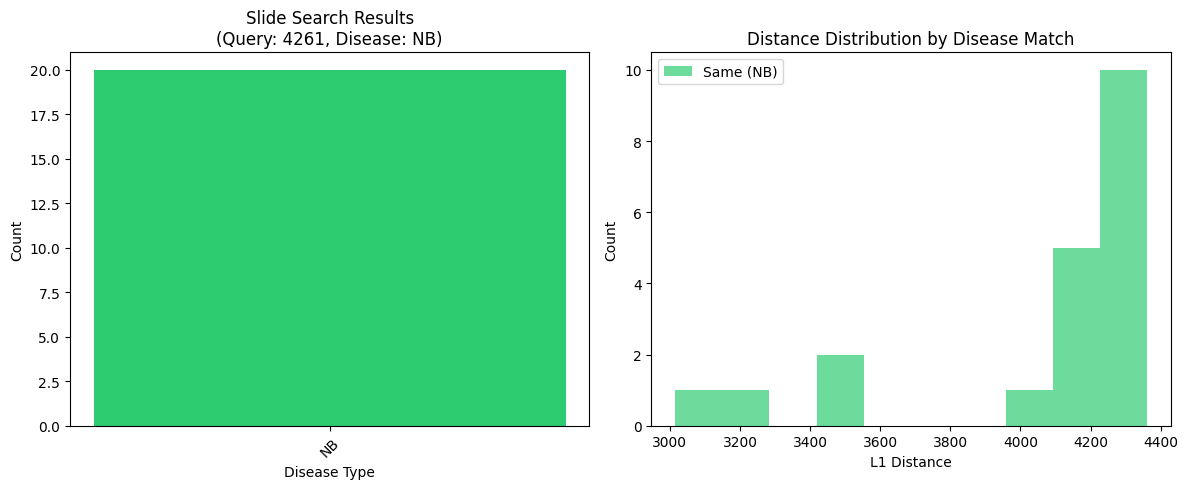

In [10]:
import matplotlib.pyplot as plt

# Disease distribution in top-20 results
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Disease distribution in slide search results
ax1 = axes[0]
disease_counts = slide_search_df['hit_disease'].value_counts()
colors = ['#2ecc71' if d == query_disease else '#3498db' for d in disease_counts.index]
ax1.bar(disease_counts.index, disease_counts.values, color=colors)
ax1.set_xlabel('Disease Type')
ax1.set_ylabel('Count')
ax1.set_title(f'Slide Search Results\n(Query: {SLIDE_ID}, Disease: {query_disease})')
ax1.tick_params(axis='x', rotation=45)

# Plot 2: Distance distribution
ax2 = axes[1]
same_disease = slide_search_df[slide_search_df['hit_disease'] == query_disease]['distance']
diff_disease = slide_search_df[slide_search_df['hit_disease'] != query_disease]['distance']

if len(same_disease) > 0:
    ax2.hist(same_disease, bins=10, alpha=0.7, label=f'Same ({query_disease})', color='#2ecc71')
if len(diff_disease) > 0:
    ax2.hist(diff_disease, bins=10, alpha=0.7, label='Different', color='#e74c3c')
ax2.set_xlabel('L1 Distance')
ax2.set_ylabel('Count')
ax2.set_title('Distance Distribution by Disease Match')
ax2.legend()

plt.tight_layout()
plt.show()

---
## 5. ROI Search

Find similar tissue regions (patches) across the reference database.

This is useful for:
- Finding morphologically similar regions in other slides
- Identifying diagnostic patterns
- Quality control and annotation transfer

In [11]:
from prosper.search import ROISearchEngine

roi_search_path = SEARCH_RESULTS_DIR / f"{SLIDE_ID}_roi_search.csv"

# Only initialize ROI engine if results are not cached
if not roi_search_path.exists():
    roi_engine = ROISearchEngine(
        top_k=5,  # Top-5 similar patches per query patch
        verbose=True
    )
    print("Loading reference patch embeddings...")
    roi_engine.load_reference_database(
        embeddings_dir=str(REFERENCE_PATCHES_DIR)
    )
    print(f"Loaded {len(roi_engine.reference_embeddings)} slides for ROI search")
else:
    print(f"[CACHED] ROI search results exist at {roi_search_path}")

Loading reference patch embeddings...


Loading embeddings:   0%|          | 0/2921 [00:00<?, ?it/s]

Loading embeddings:   0%|          | 2/2921 [00:00<03:03, 15.89it/s]

Loading embeddings:   0%|          | 5/2921 [00:00<02:40, 18.12it/s]

Loading embeddings:   0%|          | 9/2921 [00:00<02:06, 23.00it/s]

Loading embeddings:   0%|          | 12/2921 [00:00<02:26, 19.87it/s]

... (937 outputs left out)

Loading embeddings: 100%|█████████▉| 2917/2921 [02:28<00:00, 27.03it/s]

Loading embeddings: 100%|█████████▉| 2920/2921 [02:28<00:00, 24.40it/s]

Loading embeddings: 100%|██████████| 2921/2921 [02:28<00:00, 19.61it/s]

Loaded 2921 slides for ROI search
Loaded 2921 slides for ROI search


In [12]:
if roi_search_path.exists():
    print(f"[CACHED] Loading ROI results from {roi_search_path}")
    roi_df = pd.read_csv(roi_search_path)
    roi_results = None  # raw objects not available from CSV cache
else:
    # Load patch embeddings if not already in memory
    try:
        patch_embeddings
    except NameError:
        patch_emb_path = PATCH_EMB_DIR / "tmp" / f"{SLIDE_ID}.pkl"
        with open(patch_emb_path, 'rb') as f:
            patch_embeddings, mosaic = pickle.load(f)

    query_coords = np.array([m['wsi_loc'] for m in mosaic])

    print(f"Searching for 1 query patch (patch 0)...")
    roi_results = roi_engine.search(
        query_embeddings=patch_embeddings,
        query_slide_id=SLIDE_ID,
        query_coords=query_coords,
        patch_indices=[0]  # Single patch for demo
    )
    roi_df = roi_engine.results_to_dataframe(roi_results)
    roi_df['hit_disease'] = roi_df['hit_slide_id'].map(disease_map)
    roi_df.to_csv(roi_search_path, index=False)
    print(f"Saved ROI search results to: {roi_search_path}")

Searching for 1 query patch (patch 0)...


Searching patches for 4261:   0%|          | 0/1 [00:00<?, ?it/s]

Searching patches for 4261: 100%|██████████| 1/1 [00:15<00:00, 15.82s/it]

Searching patches for 4261: 100%|██████████| 1/1 [00:15<00:00, 15.82s/it]

Saved ROI search results to: output/search_results/4261_roi_search.csv


In [13]:
# Display ROI search results
print("\nROI Search Results (sample):")
print("-" * 80)
print(f"Total results: {len(roi_df)} rows")
roi_df.head(15)


ROI Search Results (sample):
--------------------------------------------------------------------------------
Total results: 5 rows


,query_slide_id,query_patch_id,query_location_x,query_location_y,hit_slide_id,hit_patch_id,hit_location_x,hit_location_y,distance,rank,hit_disease
0,4261,0,37888,32768,4369,135,25088,58368,381.580444,1,NB
1,4261,0,37888,32768,4280,1603,30208,65024,391.383881,2,NB
2,4261,0,37888,32768,4340,2048,24576,57344,394.959839,3,NB
3,4261,0,37888,32768,4376,1652,51712,54784,397.697327,4,NB
4,4261,0,37888,32768,4294,931,24064,39936,411.376862,5,NB


In [14]:
# ROI results summary
print(f"ROI search results: {roi_search_path}")
if 'hit_disease' in roi_df.columns:
    print(f"\nDisease distribution in ROI hits:")
    print(roi_df['hit_disease'].value_counts().head(10))

ROI search results: output/search_results/4261_roi_search.csv

Disease distribution in ROI hits:
hit_disease
NB    5
Name: count, dtype: int64


### 5.1 ROI Heatmap Visualization

Generate a heatmap showing the similarity of each patch in a matched slide to a query patch.
The heatmap is overlaid on the slide thumbnail for context.

In [15]:
from prosper.visualization import generate_roi_search_heatmap
from PIL import Image

# Get top hit slide from the ROI results DataFrame
query_patch_idx = 0
top_hit_row = roi_df[roi_df['query_patch_idx'] == query_patch_idx].iloc[0] if 'query_patch_idx' in roi_df.columns else roi_df.iloc[0]
top_hit_slide_id = str(top_hit_row.get('hit_slide_id', roi_df.iloc[0]['hit_slide_id']))

# Check for cached overlay
roi_overlay_path = ROI_HEATMAP_DIR / f"roi_overlay_{SLIDE_ID}_p{query_patch_idx}_{top_hit_slide_id}.png"

if roi_overlay_path.exists():
    print(f"[CACHED] ROI overlay exists at {roi_overlay_path}")
    roi_overlay_img = Image.open(roi_overlay_path)
else:
    print(f"Query: Slide {SLIDE_ID}, Patch {query_patch_idx} → Hit: {top_hit_slide_id}")
    result_paths = generate_roi_search_heatmap(
        embeddings_dir=str(REFERENCE_PATCHES_DIR),
        query_slide_id=SLIDE_ID,
        query_patch_idx=query_patch_idx,
        hit_slide_id=top_hit_slide_id,
        output_dir=str(ROI_HEATMAP_DIR),
        mosaic_path=str(MOSAIC_METADATA_PATH),
        thumbnails_dir=str(THUMBNAILS_DIR),
        dimensions_csv=str(DIMENSIONS_CSV),
        patch_size=512,
        tile_size=16,
        overlay_alpha=120
    )
    # Keep only the overlay, remove standalone heatmap
    if result_paths.get('overlay'):
        overlay_src = Path(result_paths['overlay'])
        overlay_src.rename(roi_overlay_path)
        roi_overlay_img = Image.open(roi_overlay_path)
    if result_paths.get('heatmap'):
        Path(result_paths['heatmap']).unlink(missing_ok=True)
    print(f"Saved overlay to: {roi_overlay_path}")

Query: Slide 4261, Patch 0 → Hit: 4369
Query slide 4261: 2146 patches
Hit slide 4369: 2697 patches
Query patch 0 location: [76800 26112]
Distance range: 967.26 - 1365.39


Loaded mosaic metadata with 2697 tiles (using cluster_locs)


Saved heatmap to: output/roi_heatmaps/heatmap_query_4261_patch0_hit_4369.png
Loaded slide dimensions: 123503 x 85422
Using slide dimensions from CSV: 123503 x 85422
Thumbnail dimensions: 999 x 691
Scale factors: x=0.008089, y=0.008089


Saved overlay to: output/roi_heatmaps/heatmap_query_4261_patch0_hit_4369_overlay.png
Generated overlay on thumbnail: output/roi_heatmaps/heatmap_query_4261_patch0_hit_4369_overlay.png
Saved overlay to: output/roi_heatmaps/roi_overlay_4261_p0_4369.png


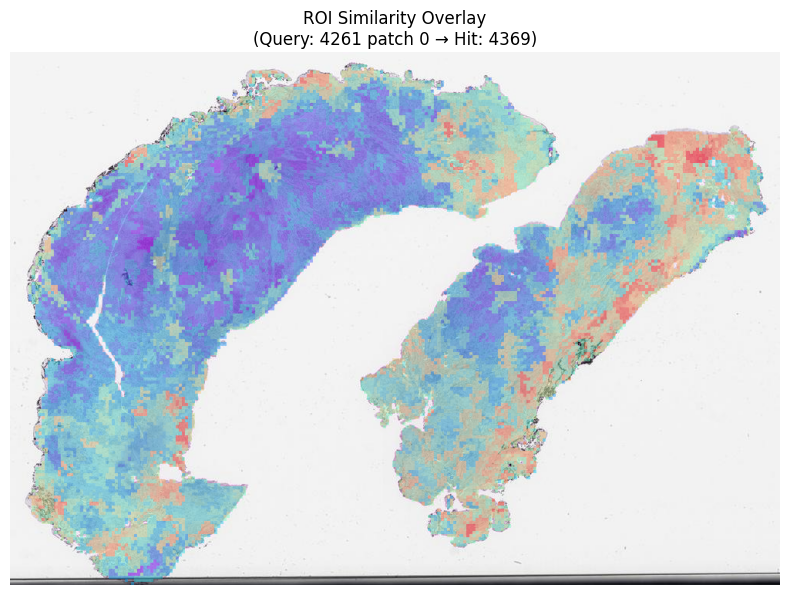

Color scale: Red (most similar) → Violet (least similar)


In [16]:
# Display ROI heatmap overlay
if 'roi_overlay_img' in dir() and roi_overlay_img is not None:
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(roi_overlay_img)
    ax.set_title(f'ROI Similarity Overlay\n(Query: {SLIDE_ID} patch {query_patch_idx} → Hit: {top_hit_slide_id})')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    print("Color scale: Red (most similar) → Violet (least similar)")
else:
    print("Overlay not generated (thumbnail may be missing)")

---
## 6. OT (Optimal Transport) Slide Comparison

Compare two slides at the patch level using Optimal Transport.
This computes a transport plan between patch distributions and gives
per-patch similarity scores, which can then be visualized as heatmaps.

**Requirements:** `pip install POT` (Python Optimal Transport library)

In [17]:
from prosper.embeddings.slide_embedding import OTSlideEmbeddingGenerator
from prosper.visualization.ot_visualization import (
    compute_per_patch_weighted_distance_scores,
    normalize_scores
)
from prosper.visualization.roi_heatmap import load_embedding_file, load_mosaic_metadata, load_slide_dimensions

# Pick the top-1 hit slide from slide search for OT comparison
ot_hit_slide_id = str(results[0]['hit_slide_id'])
ot_cache_path = OUTPUT_DIR / f"ot_result_{SLIDE_ID}_vs_{ot_hit_slide_id}.pkl"

if ot_cache_path.exists():
    print(f"[CACHED] Loading OT result from {ot_cache_path}")
    with open(ot_cache_path, 'rb') as f:
        ot_cache = pickle.load(f)
    ot_result = ot_cache['ot_result']
    D_query = ot_cache['D_query']
    D_hit = ot_cache['D_hit']
    query_mosaic_ot = ot_cache['query_mosaic']
    hit_mosaic = ot_cache['hit_mosaic']
else:
    print(f"OT comparison: Query slide {SLIDE_ID} vs Hit slide {ot_hit_slide_id}")
    query_embs, query_coords_ot = load_embedding_file(str(REFERENCE_PATCHES_DIR), SLIDE_ID)
    hit_embs, hit_coords = load_embedding_file(str(REFERENCE_PATCHES_DIR), ot_hit_slide_id)

    print(f"Query: {query_embs.shape[0]} patches, Hit: {hit_embs.shape[0]} patches")

    query_mosaic_ot = load_mosaic_metadata(str(MOSAIC_METADATA_PATH), SLIDE_ID)
    hit_mosaic = load_mosaic_metadata(str(MOSAIC_METADATA_PATH), ot_hit_slide_id)

    ot_gen = OTSlideEmbeddingGenerator(
        metric="cosine", reg=0.0, feature_dim=1280, verbose=True
    )
    ot_query_data = ot_gen.process_single_slide(query_embs.astype(np.float32), SLIDE_ID, query_mosaic_ot)
    ot_hit_data = ot_gen.process_single_slide(hit_embs.astype(np.float32), ot_hit_slide_id, hit_mosaic)

    print("Computing Optimal Transport distance (this may take a moment)...")
    ot_result = ot_gen.compute_detailed_similarity(ot_query_data, ot_hit_data)

    T, M = ot_result['T'], ot_result['M']
    D_query, D_hit = compute_per_patch_weighted_distance_scores(T, M)

    with open(ot_cache_path, 'wb') as f:
        pickle.dump({'ot_result': ot_result, 'D_query': D_query, 'D_hit': D_hit,
                     'query_mosaic': query_mosaic_ot, 'hit_mosaic': hit_mosaic}, f)

print(f"\nOT (Wasserstein) distance: {ot_result['distance']:.6f}")
print(f"Transport matrix T shape: {ot_result['T'].shape}")
print(f"Per-patch scores — Query: mean={D_query.mean():.6f}, Hit: mean={D_hit.mean():.6f}")

OT comparison: Query slide 4261 vs Hit slide 4275
Query: 2146 patches, Hit: 2536 patches


Computing Optimal Transport distance (this may take a moment)...



OT (Wasserstein) distance: 0.305673
Transport matrix T shape: (2146, 2536)
Per-patch scores — Query: mean=0.000142, Hit: mean=0.000121


### 6.1 OT Heatmap Visualization

Generate per-patch OT similarity heatmaps for both slides, overlaid on thumbnails.
Warmer colors indicate patches that contributed more to the overall slide similarity.

In [18]:
from prosper.visualization.roi_heatmap import (
    load_thumbnail, get_slide_dimensions,
    overlay_heatmap_on_thumbnail as _overlay_fn,
    generate_roi_heatmap
)

# Single side-by-side comparison image
slide_comparison_path = SLIDE_HEATMAP_DIR / f"slide_comparison_{SLIDE_ID}_vs_{ot_hit_slide_id}.png"

if slide_comparison_path.exists():
    print(f"[CACHED] Slide comparison image at {slide_comparison_path}")
    slide_comparison_img = Image.open(slide_comparison_path)
else:
    thumb_query = load_thumbnail(str(THUMBNAILS_DIR), SLIDE_ID)
    thumb_hit = load_thumbnail(str(THUMBNAILS_DIR), ot_hit_slide_id)
    dims_query = get_slide_dimensions(SLIDE_ID, str(DIMENSIONS_CSV))
    dims_hit = get_slide_dimensions(ot_hit_slide_id, str(DIMENSIONS_CSV))

    overlay_imgs = {}
    for label, mosaic_tiles, scores, thumbnail, slide_dims, sid in [
        ("query", query_mosaic_ot, D_query, thumb_query, dims_query, SLIDE_ID),
        ("hit", hit_mosaic, D_hit, thumb_hit, dims_hit, ot_hit_slide_id),
    ]:
        if mosaic_tiles is None or thumbnail is None:
            print(f"  Skipping {label}: missing mosaic or thumbnail")
            continue
        # Generate heatmap in memory (no save)
        heatmap_img = generate_roi_heatmap(
            mosaic_tiles=mosaic_tiles, distances=scores,
            patch_size=512, tile_size=16, output_path=None
        )
        overlay_img = _overlay_fn(
            heatmap_image=heatmap_img, thumbnail=thumbnail, alpha=120,
            output_path=None, mosaic_tiles=mosaic_tiles,
            distances=scores, patch_size=512, slide_dimensions=slide_dims
        )
        overlay_imgs[label] = (overlay_img, sid)

    # Stitch side-by-side and save single file
    if len(overlay_imgs) == 2:
        img_q = overlay_imgs['query'][0]
        img_h = overlay_imgs['hit'][0]
        # Resize to same height
        h = max(img_q.height, img_h.height)
        img_q = img_q.resize((int(img_q.width * h / img_q.height), h))
        img_h = img_h.resize((int(img_h.width * h / img_h.height), h))
        combined = Image.new('RGB', (img_q.width + img_h.width + 20, h), (255, 255, 255))
        combined.paste(img_q, (0, 0))
        combined.paste(img_h, (img_q.width + 20, 0))
        combined.save(slide_comparison_path)
        slide_comparison_img = combined
        print(f"Saved side-by-side comparison to: {slide_comparison_path}")
    else:
        slide_comparison_img = None
        print("Could not generate comparison (missing thumbnails or mosaic data)")

Using slide dimensions from CSV: 99599 x 60979
Thumbnail dimensions: 1000 x 612
Scale factors: x=0.010040, y=0.010036


Using slide dimensions from CSV: 109559 x 88739
Thumbnail dimensions: 999 x 809
Scale factors: x=0.009118, y=0.009117


Saved side-by-side comparison to: output/slide_heatmaps/slide_comparison_4261_vs_4275.png


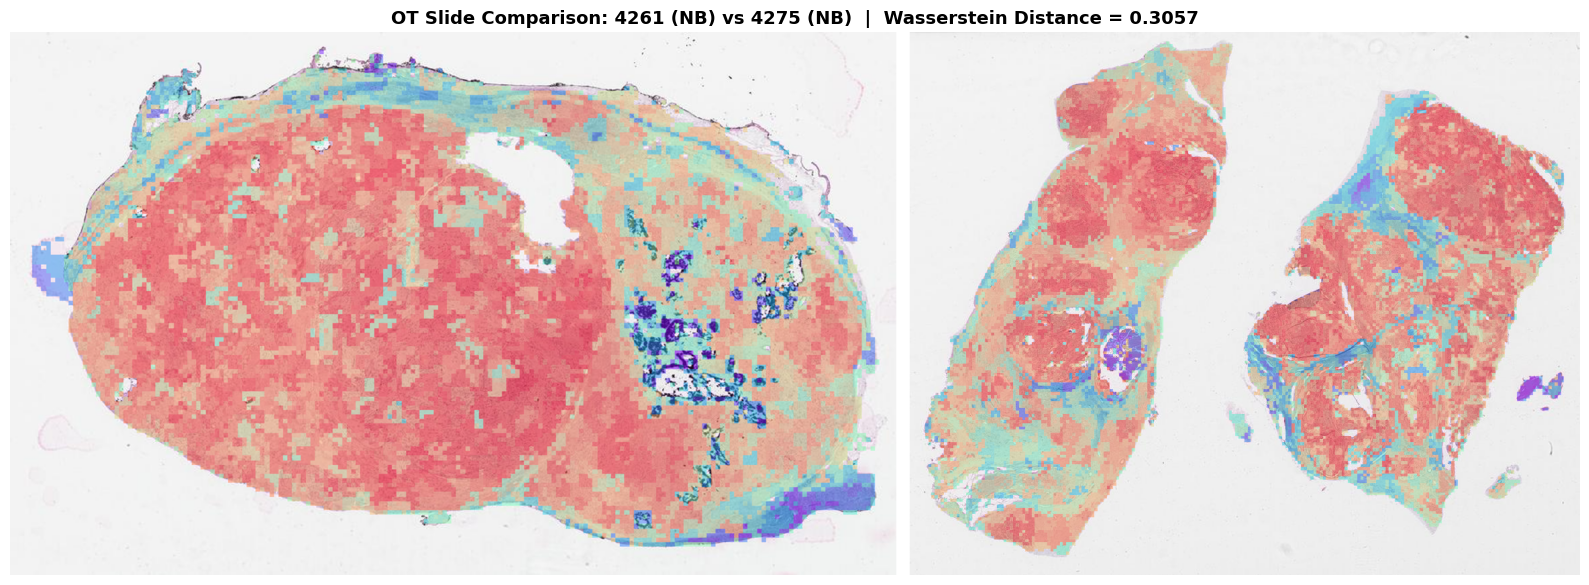

Color scale: Red (most similar / lowest OT cost) → Violet (least similar)


In [19]:
# Display side-by-side slide comparison
if slide_comparison_img is not None:
    query_disease_label = disease_map.get(SLIDE_ID, 'Unknown')
    hit_disease_label = disease_map.get(ot_hit_slide_id, 'Unknown')

    fig, ax = plt.subplots(figsize=(16, 7))
    ax.imshow(slide_comparison_img)
    ax.set_title(
        f"OT Slide Comparison: {SLIDE_ID} ({query_disease_label}) vs "
        f"{ot_hit_slide_id} ({hit_disease_label})  |  "
        f"Wasserstein Distance = {ot_result['distance']:.4f}",
        fontsize=13, fontweight='bold'
    )
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    print("Color scale: Red (most similar / lowest OT cost) → Violet (least similar)")
else:
    print("Comparison image not available")

---
## 7. Bayesian Disease Probabilities

Estimate disease likelihoods for the query slide using exponential-weighted
nearest neighbors from the full distance matrix.

The Bayesian module converts raw distances into a probability distribution
over all disease types, controlled by two parameters:
- **n_neighbors**: how many neighbors to consider (default: 20)
- **temperature**: smoothing parameter — larger values produce softer distributions (default: 20)

In [20]:
from prosper.bayesian import compute_disease_probs

N_NEIGHBORS = 20
TEMPERATURE = 20.0
bayesian_json_path = BAYESIAN_DIR / f"disease_probs_{SLIDE_ID}.json"
bayesian_csv_path = BAYESIAN_DIR / f"disease_probs_{SLIDE_ID}.csv"

if bayesian_json_path.exists():
    print(f"[CACHED] Loading Bayesian results from {bayesian_json_path}")
    with open(bayesian_json_path, 'r') as f:
        cached = json.load(f)
    nonzero_probs = cached['probabilities']
else:
    print("Computing Bayesian disease probabilities...")
    print("=" * 60)

    full_distances = cdist(ref_matrix, ref_matrix, metric='cityblock')
    class_labels = [disease_map.get(sid, 'UNKNOWN') for sid in ref_slide_ids]

    list_of_dicts, prob_df = compute_disease_probs(
        distance_matrix=full_distances,
        class_labels=class_labels,
        n_neighbors=N_NEIGHBORS,
        T=TEMPERATURE,
        test_slide_ids=ref_slide_ids,
    )

    query_idx = ref_slide_ids.index(SLIDE_ID)
    query_probs = list_of_dicts[query_idx]
    nonzero_probs = {d: p for d, p in sorted(query_probs.items(), key=lambda x: -x[1]) if p > 1e-8}

    with open(bayesian_json_path, 'w') as f:
        json.dump({
            'slide_id': SLIDE_ID,
            'n_neighbors': N_NEIGHBORS,
            'temperature': TEMPERATURE,
            'probabilities': nonzero_probs,
        }, f, indent=2)
    prob_df.loc[[SLIDE_ID]].to_csv(bayesian_csv_path)
    print(f"Saved to: {bayesian_json_path}")

print(f"\nDisease probabilities for slide {SLIDE_ID} (top entries):")
print("-" * 40)
for disease, prob in list(nonzero_probs.items())[:10]:
    marker = " ← query disease" if disease == query_disease else ""
    print(f"  {disease:<20s} {prob:.6f}{marker}")

Computing Bayesian disease probabilities...


Saved to: output/bayesian/disease_probs_4261.json

Disease probabilities for slide 4261 (top entries):
----------------------------------------
  NB                   1.000000 ← query disease


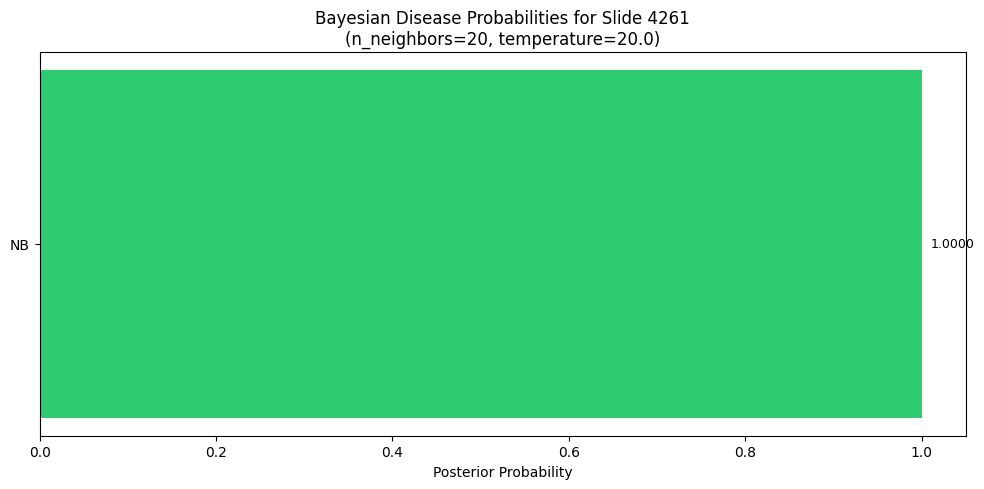

Green = query disease (NB), Blue = other diseases


In [21]:
# Visualize Bayesian disease probability distribution
fig, ax = plt.subplots(figsize=(10, 5))

diseases_sorted = list(nonzero_probs.keys())
probs_sorted = list(nonzero_probs.values())
colors = ['#2ecc71' if d == query_disease else '#3498db' for d in diseases_sorted]

ax.barh(diseases_sorted[::-1], probs_sorted[::-1], color=colors[::-1])
ax.set_xlabel('Posterior Probability')
ax.set_title(f'Bayesian Disease Probabilities for Slide {SLIDE_ID}\n'
             f'(n_neighbors={N_NEIGHBORS}, temperature={TEMPERATURE})')
ax.set_xlim(0, 1.05)

# Add probability values as text
for i, (d, p) in enumerate(zip(diseases_sorted[::-1], probs_sorted[::-1])):
    ax.text(p + 0.01, i, f'{p:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print(f"Green = query disease ({query_disease}), Blue = other diseases")

---
## 8. LLM Summarization

Generate a grounded narrative from the search results using an LLM.

The summarization pipeline has two steps:
1. **Build LLM-ready JSON** — Combine neighbor metadata, similarity scores, and Bayesian
   probabilities into a structured payload (`prosper.llm.build_json_for_slide`)
2. **Generate summary** — Send the payload to a GPT model with a grounded prompt that
   enforces inline citations, factual claims verification, and provenance checks
   (`prosper.llm.attempt_llm_summary_from_payload`)

**Requirements:**
- Azure OpenAI or OpenAI API key set in environment variables
- Rich metadata CSV with clinical columns (age, sex, site, treatment, etc.)

### 8.1 Build LLM-Ready JSON Payload

Construct a structured JSON with the query slide's metadata, its top-k neighbors,
and the Bayesian disease probabilities.

In [22]:
from prosper.llm import load_results_new, load_metadata, build_json_for_slide

K_NEIGHBORS = 5
llm_json_path = LLM_DIR / f"slide_{SLIDE_ID}.json"

if llm_json_path.exists():
    print(f"[CACHED] Loading LLM payload from {llm_json_path}")
    with open(llm_json_path, 'r') as f:
        payload = json.load(f)
else:
    print("Building LLM-ready JSON payload...")
    sim_matrix = load_results_new(str(REFERENCE_MATRIX_PATH))
    rich_metadata = load_metadata(str(RICH_METADATA_PATH))
    payload = build_json_for_slide(sim_matrix, rich_metadata, slide_id=SLIDE_ID, k=K_NEIGHBORS)
    payload['probabilities'] = nonzero_probs
    with open(llm_json_path, 'w') as f:
        json.dump(payload, f, indent=2)
    print(f"Saved to: {llm_json_path}")

print(f"\nCurrent case: {payload['current_case']['case_id']}")
print(f"  Tumor group: {payload['current_case'].get('tumor_group', 'N/A')}")
print(f"\nNeighbors ({K_NEIGHBORS}):")
for i, n in enumerate(payload['neighbors'], 1):
    print(f"  {i}. {n['case_id']} ({n.get('tumor_group', '?')}) - distance: {n['similarity']:.2f}")
print(f"\nBayesian probabilities (top 3):")
for d, p in list(nonzero_probs.items())[:3]:
    print(f"  {d}: {p:.4f}")

Building LLM-ready JSON payload...
Non-square matrix detected ((2921, 12800)). Computing pairwise L1 distances...


Computed distance matrix: (2921, 2921)
Size of metadata: 2968
Saved to: output/llm/slide_4261.json

Current case: SJNBL071609_D1
  Tumor group: NB

Neighbors (5):
  1. SJNBL031947_D2 (NB) - distance: 3013.84
  2. SJNBL071580_D2 (NB) - distance: 3187.36
  3. SJNBL031886_D2 (NB) - distance: 3465.78
  4. SJNBL071574_D2 (NB) - distance: 3541.07
  5. SJNBL071485_D1 (NB) - distance: 4052.99

Bayesian probabilities (top 3):
  NB: 1.0000


### 8.2 Generate LLM Summary

Send the payload to the LLM for grounded summarization. The model produces:
- A clinician-friendly narrative (≤200 words) with inline `[case_id]` citations
- Structured claims for post-hoc verification
- Treatment status, discrepant flag, and Bayesian probabilities in the opening sentence

> **Note:** Requires `AZURE_OPENAI_ENDPOINT`, `AZURE_OPENAI_API_KEY`, `AZURE_OPENAI_API_VERSION`,
> and `AZURE_OPENAI_DEPLOYMENT` environment variables to be set (or `OPENAI_API_KEY` for OpenAI).

In [23]:
from prosper.llm import attempt_llm_summary_from_payload, MEDICAL_DISCLAIMER
import subprocess

# Load real LLM credentials from llm_env.local.sh if it exists
# (Create it from the template: cp llm_env.sh llm_env.local.sh && edit)
env_file = Path("llm_env.local.sh")
if env_file.exists():
    print(f"Loading LLM credentials from {env_file} ...")
    out = subprocess.check_output(f"source {env_file} && env", shell=True, executable="/bin/bash")
    for line in out.decode().splitlines():
        if "=" in line and any(k in line for k in ["AZURE_OPENAI", "OPENAI_API_KEY"]):
            key, val = line.split("=", 1)
            os.environ[key] = val
            print(f"  Set {key}")
else:
    print("No llm_env.local.sh found — using existing env vars.")
    print("To use real LLM: cp llm_env.sh llm_env.local.sh && edit with your keys")

has_key = bool(os.environ.get("AZURE_OPENAI_API_KEY") or os.environ.get("OPENAI_API_KEY"))
print(f"LLM API key available: {has_key}")

summary_path = LLM_DIR / f"summary_{SLIDE_ID}.txt"

if summary_path.exists():
    print(f"\n[CACHED] Loading LLM summary from {summary_path}")
    llm_text = summary_path.read_text()
    print(f"\n{llm_text}")
else:
    print("\nGenerating LLM summary...")
    print("=" * 60)
    llm_text, accepted = attempt_llm_summary_from_payload(payload)

    if llm_text and not llm_text.startswith("ERROR:"):
        label = "LLM Summary" if accepted else "LLM Summary (truncated)"
        print(f"\n{label}:\n")
        print(llm_text)
        print(f"\n{MEDICAL_DISCLAIMER}")
        with open(summary_path, 'w') as f:
            f.write(f"{label}: {llm_text}\n\n{MEDICAL_DISCLAIMER}\n")
        print(f"\nSaved to: {summary_path}")
    elif llm_text:
        print(f"\n{llm_text}")
    else:
        print("\nLLM not available. See llm_env.sh for setup instructions.")

No llm_env.local.sh found — using existing env vars.
To use real LLM: cp llm_env.sh llm_env.local.sh && edit with your keys
LLM API key available: True

Generating LLM summary...

LLM Summary:

Neighbors support NB (votes: {'NB': 4, 'Ganglioneuroblastoma': 1}) [SJNBL031947_D2, SJNBL071580_D2, SJNBL031886_D2, SJNBL071574_D2]. Similarity mean 3452.21 range 3013.84-4052.99 (lower is better) [SJNBL031947_D2, SJNBL071580_D2, SJNBL031886_D2, SJNBL071574_D2, SJNBL071485_D1]. Current case: age=23 mo, sex=F, site=Periadrenal (P), tumor_group=NB, diagnosis=NB, met=Primary. Discrepant neighbors: SJNBL071485_D1:Ganglioneuroblastoma similarity=4052.99 [SJNBL071485_D1].

DISCLAIMER: This AI-generated summary is intended to support, not replace, clinical judgment. All findings should be independently verified by a qualified pathologist before any clinical decision-making.

Saved to: output/llm/summary_4261.txt


---
## Summary

This notebook demonstrated the complete PROSPER pipeline:

1. **Mosaic Generation** - Extracted tissue patches from WSI
2. **Patch Embedding** - Generated Virchow2 embeddings (first 1280 features used)
3. **Slide Embedding** - Aggregated to slide-level using SAMPLER/percentiles (10 x 1280 = 12800-dim)
4. **Slide Search** - Found morphologically similar slides with visualization
5. **ROI Search** - Found similar tissue regions with heatmap overlays
6. **OT Slide Comparison** - Computed Optimal Transport between slides with per-patch heatmaps
7. **Bayesian Disease Probabilities** - Estimated disease likelihoods from distance-weighted neighbors
8. **LLM Summarization** - Generated grounded case reports with citations

### Output Files (all under `examples/output/`)
- `mosaic/` - Mosaic patches and metadata
- `patch_embeddings/` - Patch embeddings
- `slide_embeddings/` - Slide embedding
- `search_results/` - Slide and ROI search results
- `roi_heatmaps/` - ROI similarity overlay images
- `slide_heatmaps/` - Side-by-side OT slide comparison overlays
- `bayesian/` - Bayesian disease probability estimates
- `llm/` - LLM JSON payloads and narrative summaries

> **Note:** All steps check for cached results on re-run. Delete `examples/output/` to force a fresh run.
>
> **LLM setup:** Copy `llm_env.sh` → `llm_env.local.sh`, fill in your API keys, then `source llm_env.local.sh` before running.

### Key Data Files
- `data/metadata/slide_dimensions.csv` - Slide dimensions for accurate heatmap coordinate mapping
- `data/mosaics/comet_mosaics.pkl` - Mosaic cluster locations for full tissue coverage
- `data/thumbnails/` - Slide thumbnails for overlay visualization
- `data/metadata/final_scan_id_disease_map_rich_data.csv` - Rich metadata for LLM summarization
- `data/slide_embeddings/virchow2_sampler.pkl` - Reference slide embedding database (Virchow2 + SAMPLER)

### Next Steps
- Process more slides by changing `SLIDE_PATH`
- Try different patch models: `virchow2`, `uni2`, `gigapath`
- Try different slide similarity formulations: `percentile`, `bob`, `ot`
- Adjust Bayesian parameters (`n_neighbors`, `temperature`) for different probability sharpness
- Customize the LLM system prompt in `prosper.llm.summarizer` for your use case

In [24]:
print("Demo complete!")
print(f"\nAll outputs in: {OUTPUT_DIR.resolve()}")
print(f"\nGenerated files:")
for label, path in [
    ("Slide search", slide_search_path),
    ("ROI search", roi_search_path),
    ("ROI heatmap overlay", roi_overlay_path if 'roi_overlay_path' in dir() else None),
    ("Slide comparison", slide_comparison_path if 'slide_comparison_path' in dir() else None),
    ("Bayesian probs", bayesian_json_path),
    ("LLM payload", llm_json_path),
    ("LLM summary", summary_path),
]:
    exists = Path(path).exists() if path else False
    tag = "[OK]" if exists else "[--]"
    print(f"  {tag} {label}: {path}")
print(f"\nRe-run the notebook to use cached results (instant).")

Demo complete!

All outputs in: /research_jude/rgs01_jude/dept/DNB/core_operations/ImageAnalysis/Core/Haoran/comet-github/examples/output

Generated files:
  [OK] Slide search: output/search_results/4261_slide_search.csv
  [OK] ROI search: output/search_results/4261_roi_search.csv
  [OK] ROI heatmap overlay: output/roi_heatmaps/roi_overlay_4261_p0_4369.png
  [OK] Slide comparison: output/slide_heatmaps/slide_comparison_4261_vs_4275.png
  [OK] Bayesian probs: output/bayesian/disease_probs_4261.json
  [OK] LLM payload: output/llm/slide_4261.json
  [OK] LLM summary: output/llm/summary_4261.txt

Re-run the notebook to use cached results (instant).
